In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import EfficientNetB0

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from collections import defaultdict
from tqdm import tqdm

import keras_cv


c:\Users\Uday p\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_DIR = "Skin Disease Dataset"

IMG_SIZE = 224
INPUT_SHAPE = (224, 224, 3)
BATCH_SIZE = 32
LIMIT_PER_CLASS = 500


In [3]:
classes = sorted(os.listdir(DATA_DIR))
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)


Classes: ['Acitinic Keratosis', 'Dermatofibroma', 'Nevus', 'Pigmented Benign Keratosis', 'Seborrheic Keratosis', 'Vascular Lesion']
Number of classes: 6


In [4]:
data_dict = defaultdict(list)
root_images = []
root_labels = []
error_count = 0

for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    images = os.listdir(class_path)

    for img_name in tqdm(images, desc=f"Loading {class_name}"):
        try:
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            data_dict[class_name].append(image)
            root_images.append(image)
            root_labels.append(class_name)
        except:
            error_count += 1

print("Errors:", error_count)
print("Total images loaded:", len(root_images))

Loading Vascular Lesion: 100%|██████████| 290/290 [00:04<00:00, 58.79it/s] 

Errors: 2
Total images loaded: 2688


Acitinic Keratosis            500
Nevus                         500
Pigmented Benign Keratosis    500
Seborrheic Keratosis          500
Dermatofibroma                399
Vascular Lesion               289
dtype: int64


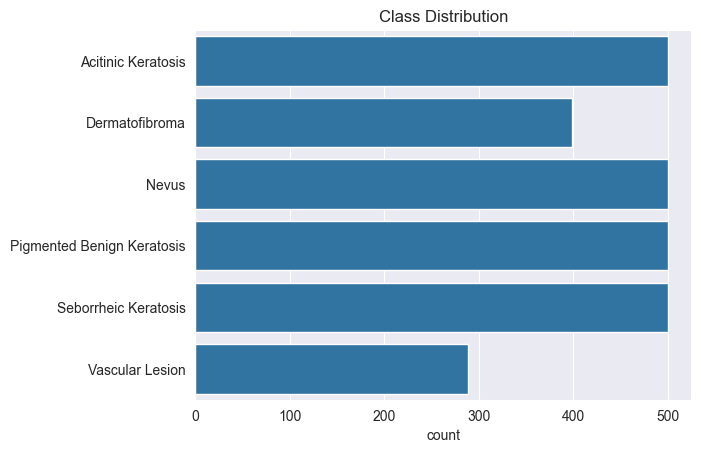

In [5]:
label_counts = pd.Series(root_labels).value_counts()
print(label_counts)

sns.countplot(y=root_labels)
plt.title("Class Distribution")
plt.show()


In [6]:
x_arr = np.array(root_images, dtype=np.float32)

y_arr = tf.one_hot(
    [classes.index(lbl) for lbl in root_labels],
    num_classes
).numpy()

print(x_arr.shape, y_arr.shape)


(2688, 224, 224, 3) (2688, 6)


In [7]:
image_per_class = 1000
mix_per_batch = 42

mixup = keras_cv.layers.Augmenter([keras_cv.layers.MixUp()])

root_label_df = pd.DataFrame({"dx": root_labels})
count_dict = {label: len(imgs) for label, imgs in data_dict.items()}

x_tensor = tf.constant(x_arr)
y_tensor = tf.constant(y_arr)

x_tensor_mix, y_tensor_mix = None, None

for label, count in count_dict.items():
    num_mix = ((image_per_class - count) // mix_per_batch) * mix_per_batch

    for _ in range(num_mix // mix_per_batch):
        idx = np.random.choice(
            root_label_df[root_label_df.dx == label].index,
            mix_per_batch,
            replace=False
        )

        mix_out = mixup({
            "images": tf.gather(x_tensor, idx),
            "labels": tf.gather(y_tensor, idx)
        })

        if x_tensor_mix is None:
            x_tensor_mix = mix_out["images"]
            y_tensor_mix = mix_out["labels"]
        else:
            x_tensor_mix = tf.concat([x_tensor_mix, mix_out["images"]], axis=0)
            y_tensor_mix = tf.concat([y_tensor_mix, mix_out["labels"]], axis=0)

x = np.concatenate([x_arr, x_tensor_mix.numpy()], axis=0)
y = np.concatenate([y_arr, y_tensor_mix.numpy()], axis=0)

print(x.shape, y.shape)


(5796, 224, 224, 3) (5796, 6)


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
x=preprocess_input(x)

In [12]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)


x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)


In [13]:
from tensorflow.keras import layers

# -------------------------------
# Channel Attention
# -------------------------------
def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    shared_dense_1 = layers.Dense(channel // ratio, activation='relu')
    shared_dense_2 = layers.Dense(channel)

    avg_pool = layers.GlobalAveragePooling2D()(input_feature)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = shared_dense_2(shared_dense_1(avg_pool))

    max_pool = layers.GlobalMaxPooling2D()(input_feature)
    max_pool = layers.Reshape((1, 1, channel))(max_pool)
    max_pool = shared_dense_2(shared_dense_1(max_pool))

    attention = layers.Activation('sigmoid')(avg_pool + max_pool)
    return layers.Multiply()([input_feature, attention])


# -------------------------------
# Spatial Attention (FIXED)
# -------------------------------
def spatial_attention(input_feature):
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True)
    )(input_feature)

    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True)
    )(input_feature)

    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])

    attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)

    return layers.Multiply()([input_feature, attention])


# -------------------------------
# CBAM Block
# -------------------------------
def cbam_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x


In [14]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=INPUT_SHAPE
)

base_model.trainable = False  # Transfer learning

x = base_model.output
x = cbam_block(x)              # 🔥 CBAM ADDED HERE
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

output = layers.Dense(num_classes, activation="softmax")(x)

model = Model(base_model.input, output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,795,308 (18.29 MB)

 Trainable params: 743,177 (2.83 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [15]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 124s 751ms/step - accuracy: 0.2999 - loss: 1.8713 - val_accuracy: 0.6086 - val_loss: 1.5966
Epoch 2/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 105s 724ms/step - accuracy: 0.6013 - loss: 1.0888 - val_accuracy: 0.6931 - val_loss: 1.2710
Epoch 3/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 146s 750ms/step - accuracy: 0.6802 - loss: 0.8805 - val_accuracy: 0.7672 - val_loss: 0.8869
Epoch 4/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 107s 737ms/step - accuracy: 0.7359 - loss: 0.7328 - val_accuracy: 0.8086 - val_loss: 0.6163
Epoch 5/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 108s 744ms/step - accuracy: 0.7794 - loss: 0.6201 - val_accuracy: 0.8603 - val_loss: 0.4819
Epoch 6/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 111s 767ms/step - accuracy: 0.8115 - loss: 0.5470 - val_accuracy: 0.8638 - val_loss: 0.4195
Epoch 7/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 114s 785ms/step - accuracy: 0.8415 - loss: 0.4687 - val_accuracy: 0.8793 - val_loss: 0.3874
Epoch 8/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 113s 777ms/step - accuracy: 0.8644 -

In [16]:
loss, acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", acc)

19/19 ━━━━━━━━━━━━━━━━━━━━ 12s 614ms/step - accuracy: 0.9072 - loss: 0.2636
Test Accuracy: 0.9017241597175598


In [ ]:
y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=classes))

19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 501ms/step
                            precision    recall  f1-score   support

        Acitinic Keratosis       0.89      0.96      0.92        96
            Dermatofibroma       0.96      0.92      0.94        99
                     Nevus       0.96      0.97      0.96        96
Pigmented Benign Keratosis       0.91      0.94      0.92        96
      Seborrheic Keratosis       0.90      0.85      0.87        97
           Vascular Lesion       0.98      0.97      0.97        96

                  accuracy                           0.93       580
                 macro avg       0.93      0.93      0.93       580
              weighted avg       0.93      0.93      0.93       580



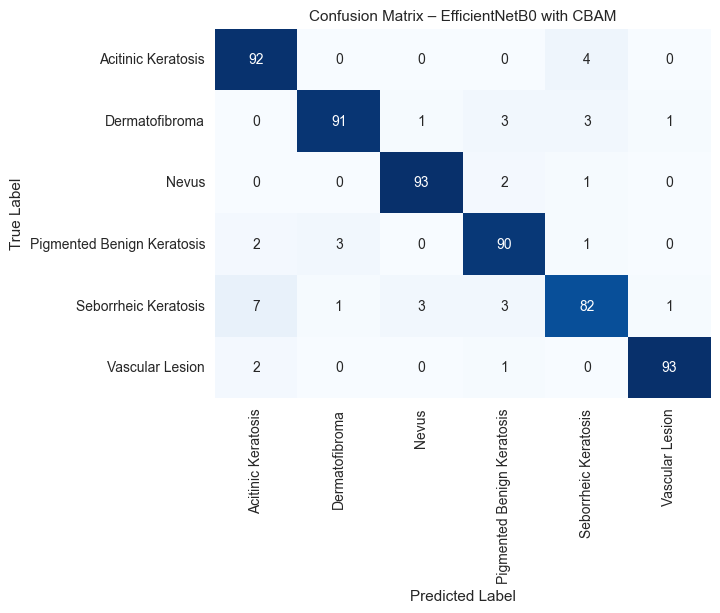

In [ ]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes,
            yticklabels=classes,
            cmap="Blues",
            cbar=False)
plt.title("Confusion Matrix – EfficientNetB0 with CBAM", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
cbar=False
plt.show()


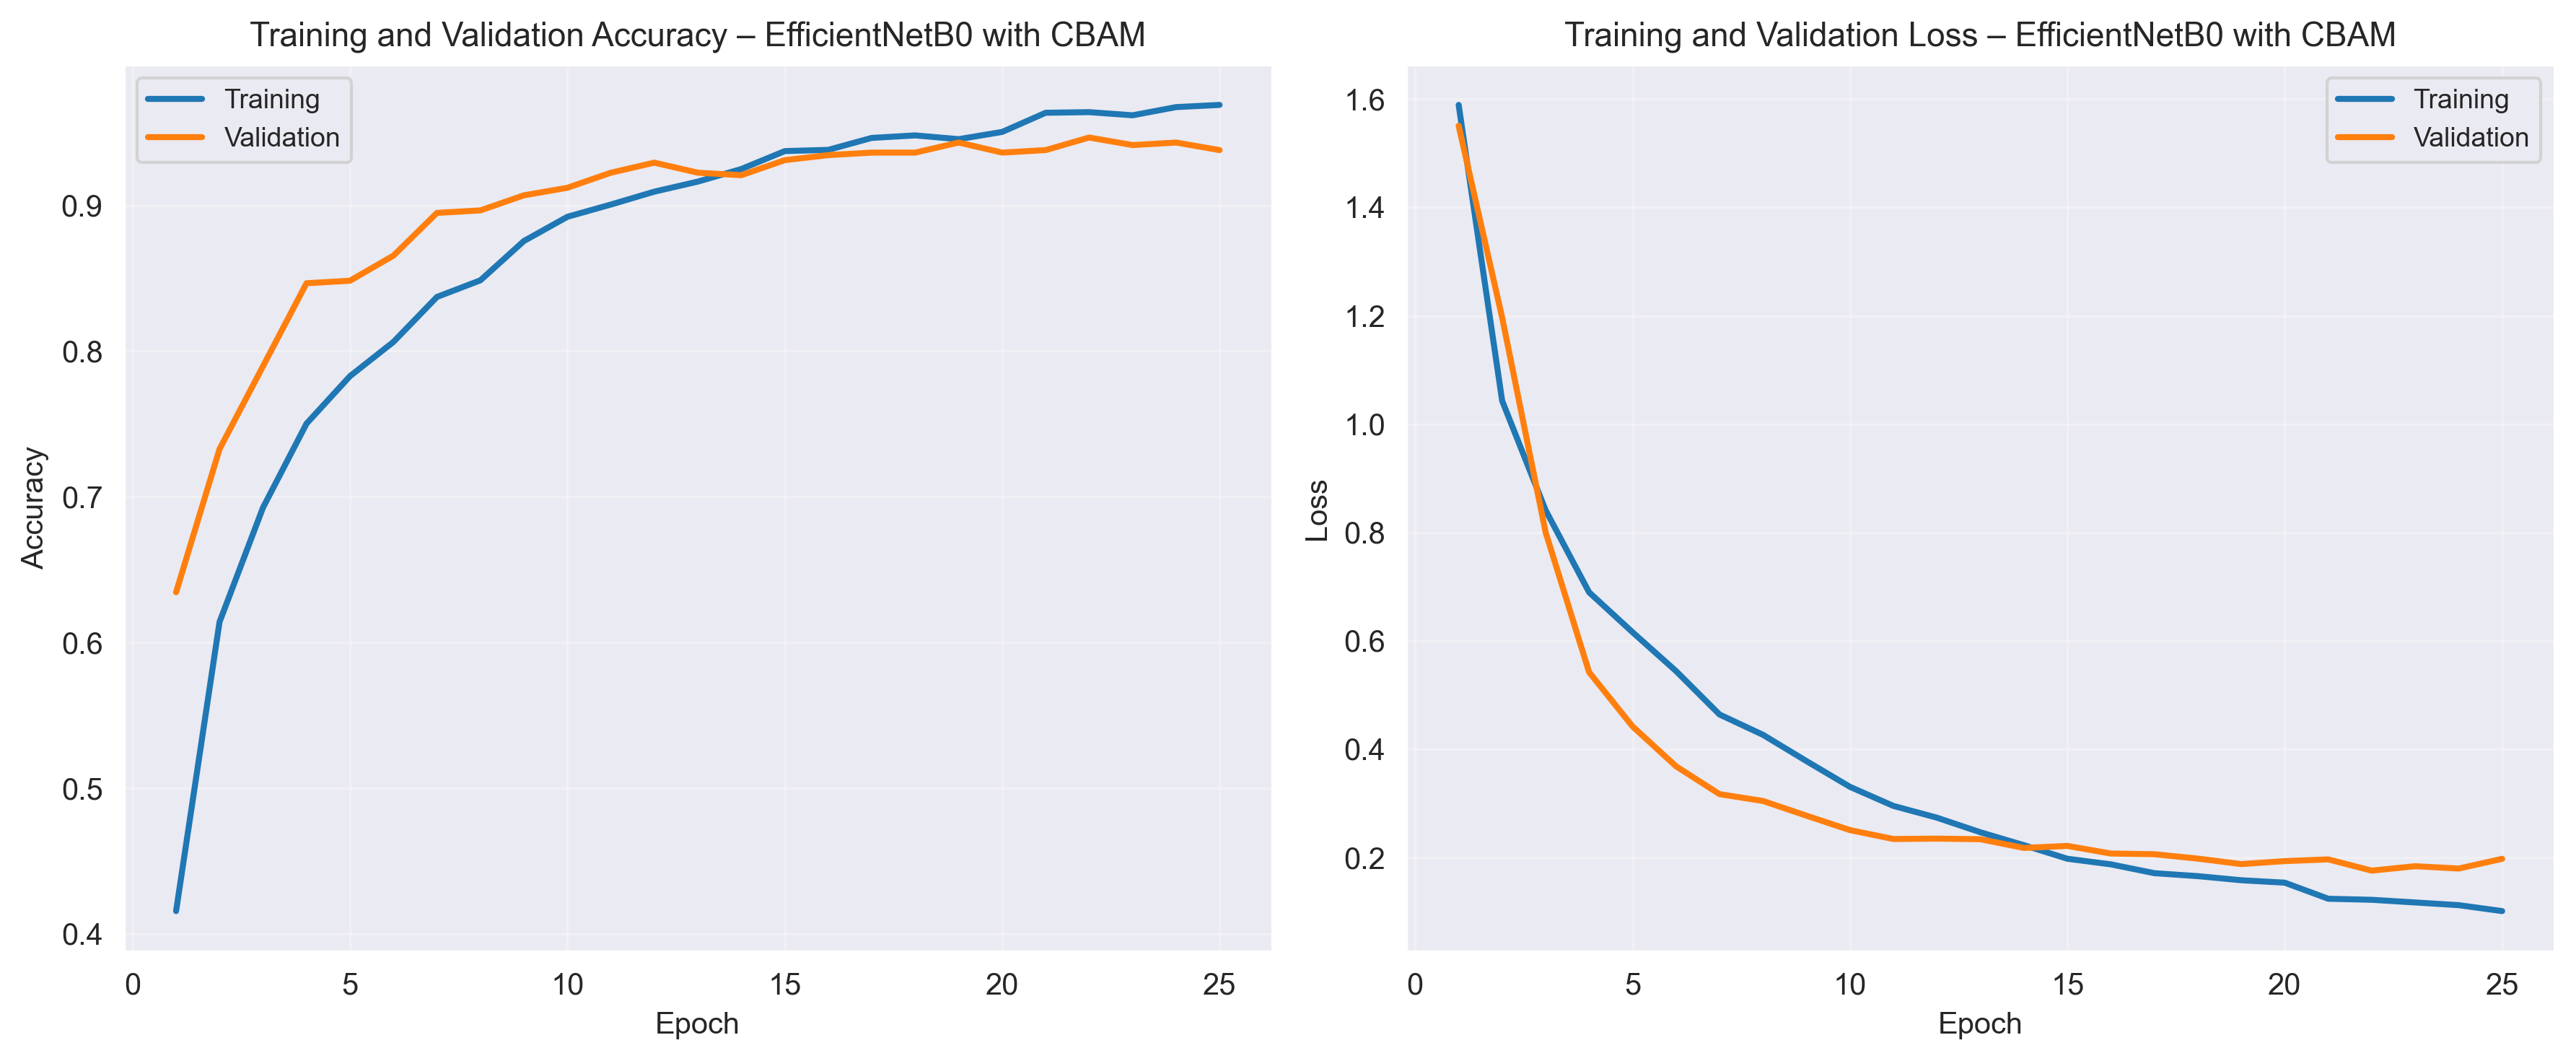

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(12, 5), dpi=300)

# ---------------- Accuracy Plot ----------------
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_accuracy'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Accuracy – EfficientNetB0 with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)

# ---------------- Loss Plot ----------------
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_loss'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Loss – EfficientNetB0 with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 474ms/step


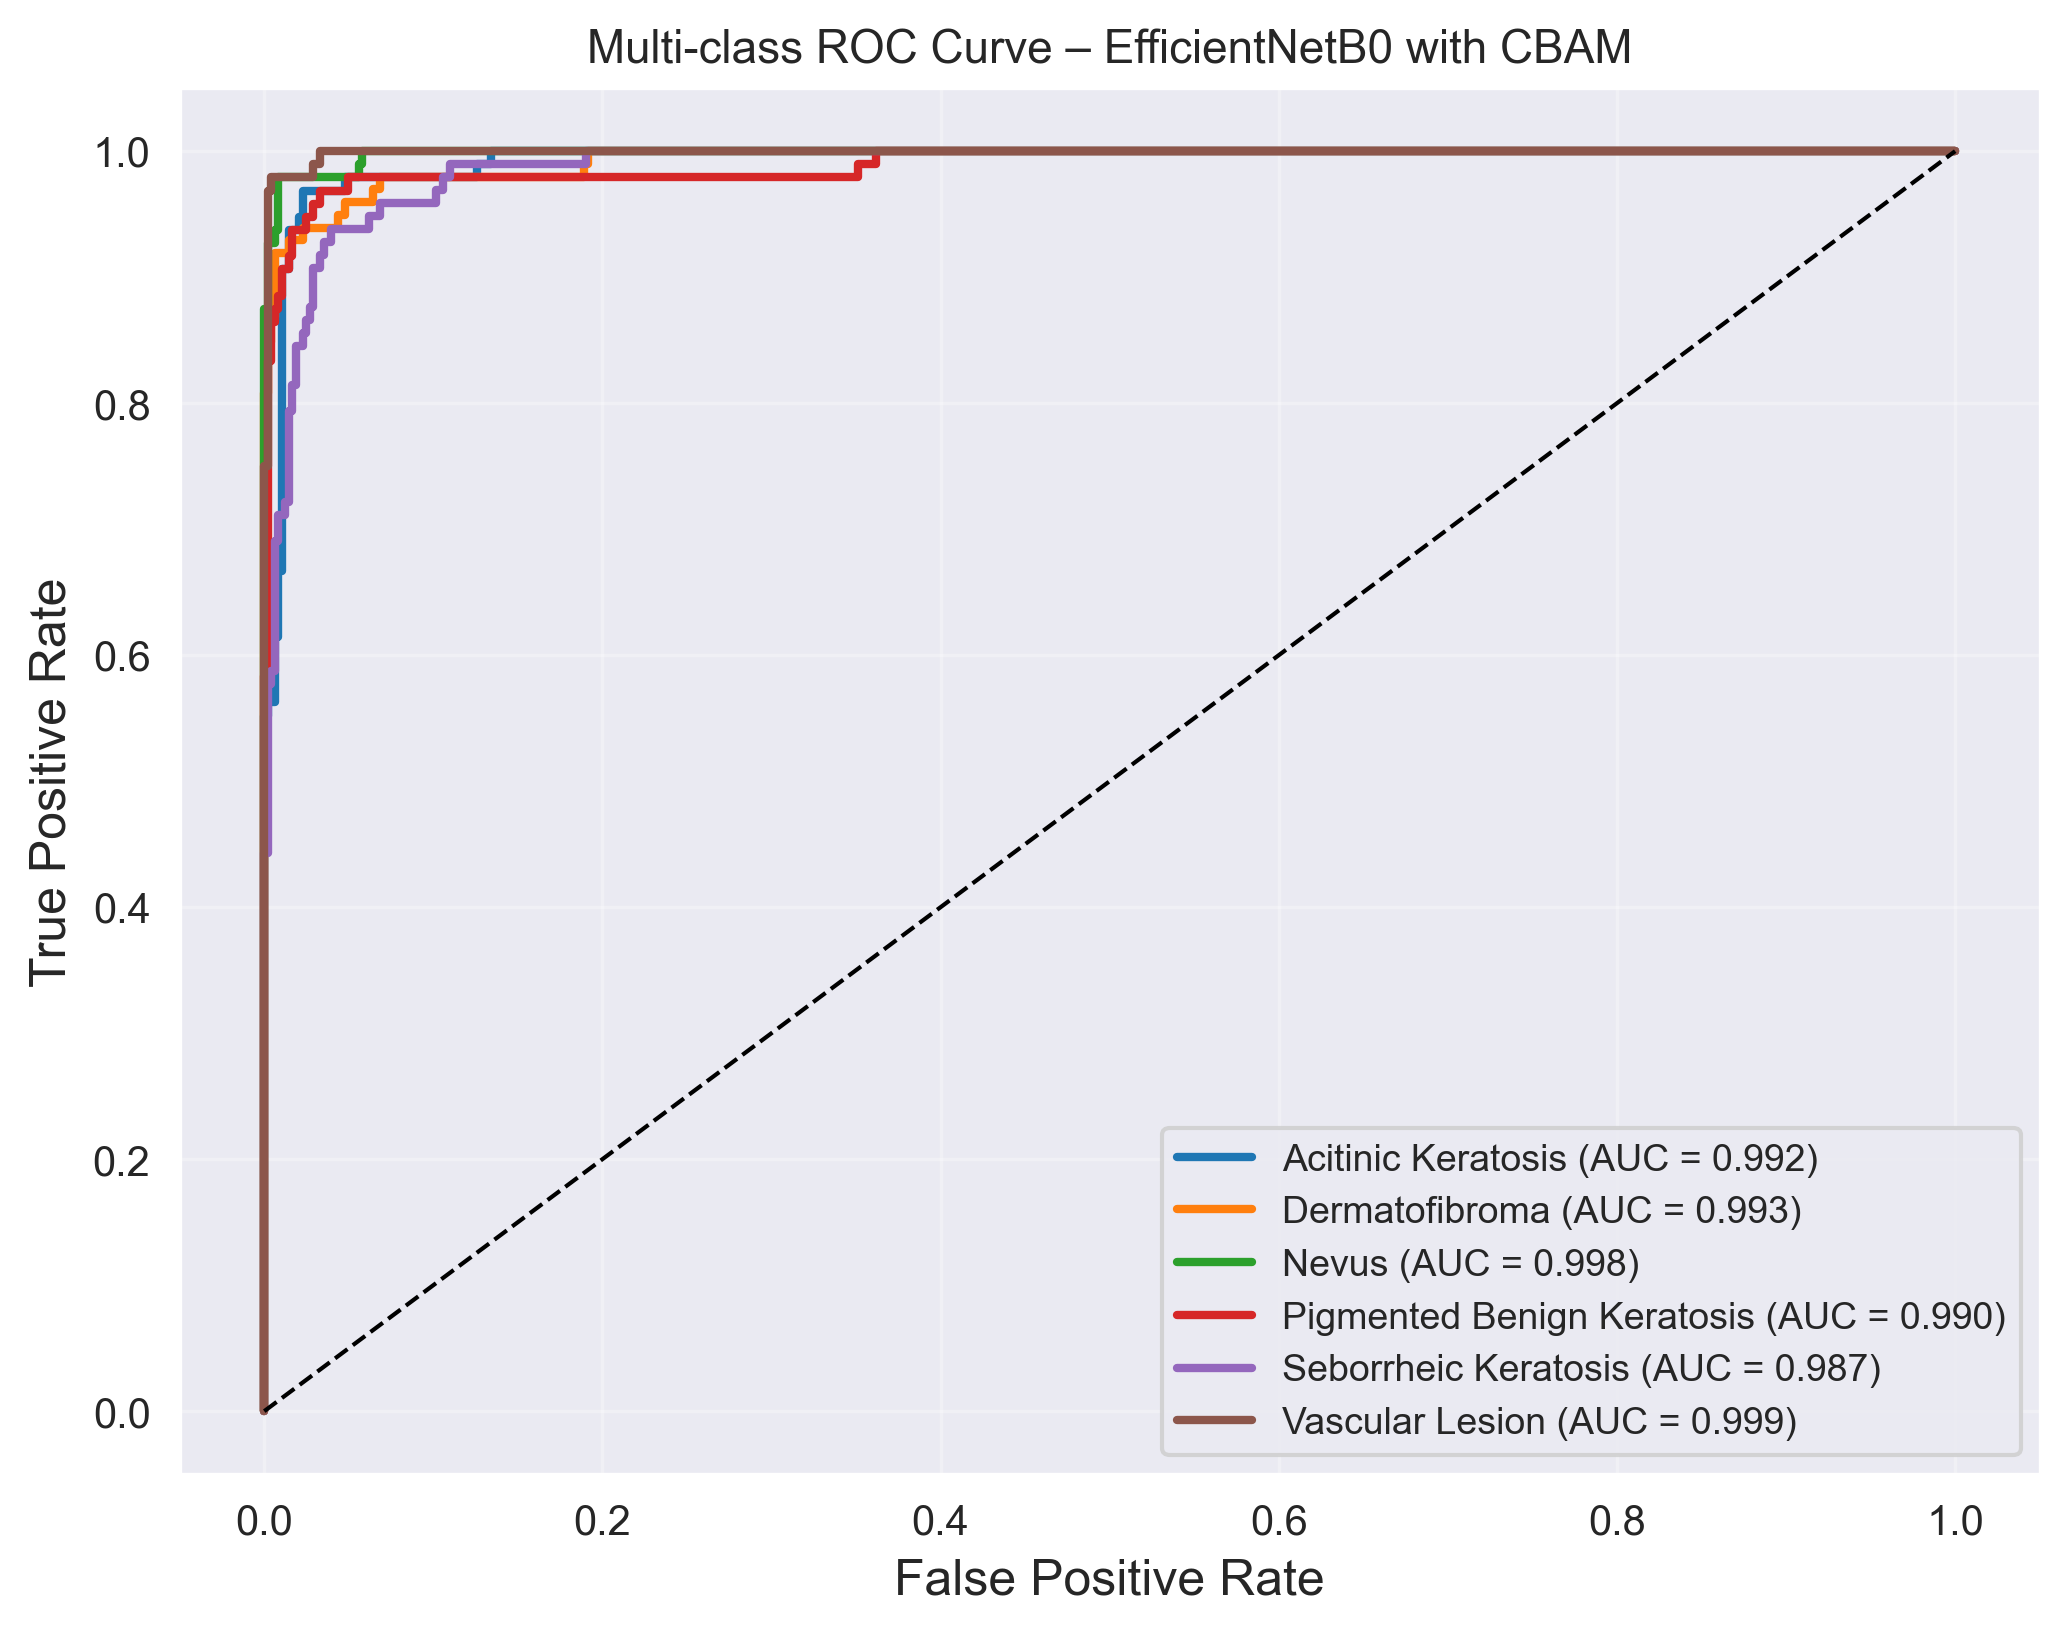

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Predict probabilities
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Compute ROC curve and AUC
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], linewidth=2,
             label=f"{classes[i]} (AUC = {roc_auc[i]:.3f})")

# Random classifier
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Multi-class ROC Curve – EfficientNetB0 with CBAM", fontsize=11)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

# Save for research paper
plt.savefig("roc_curve.png", dpi=300, bbox_inches='tight')

plt.show()

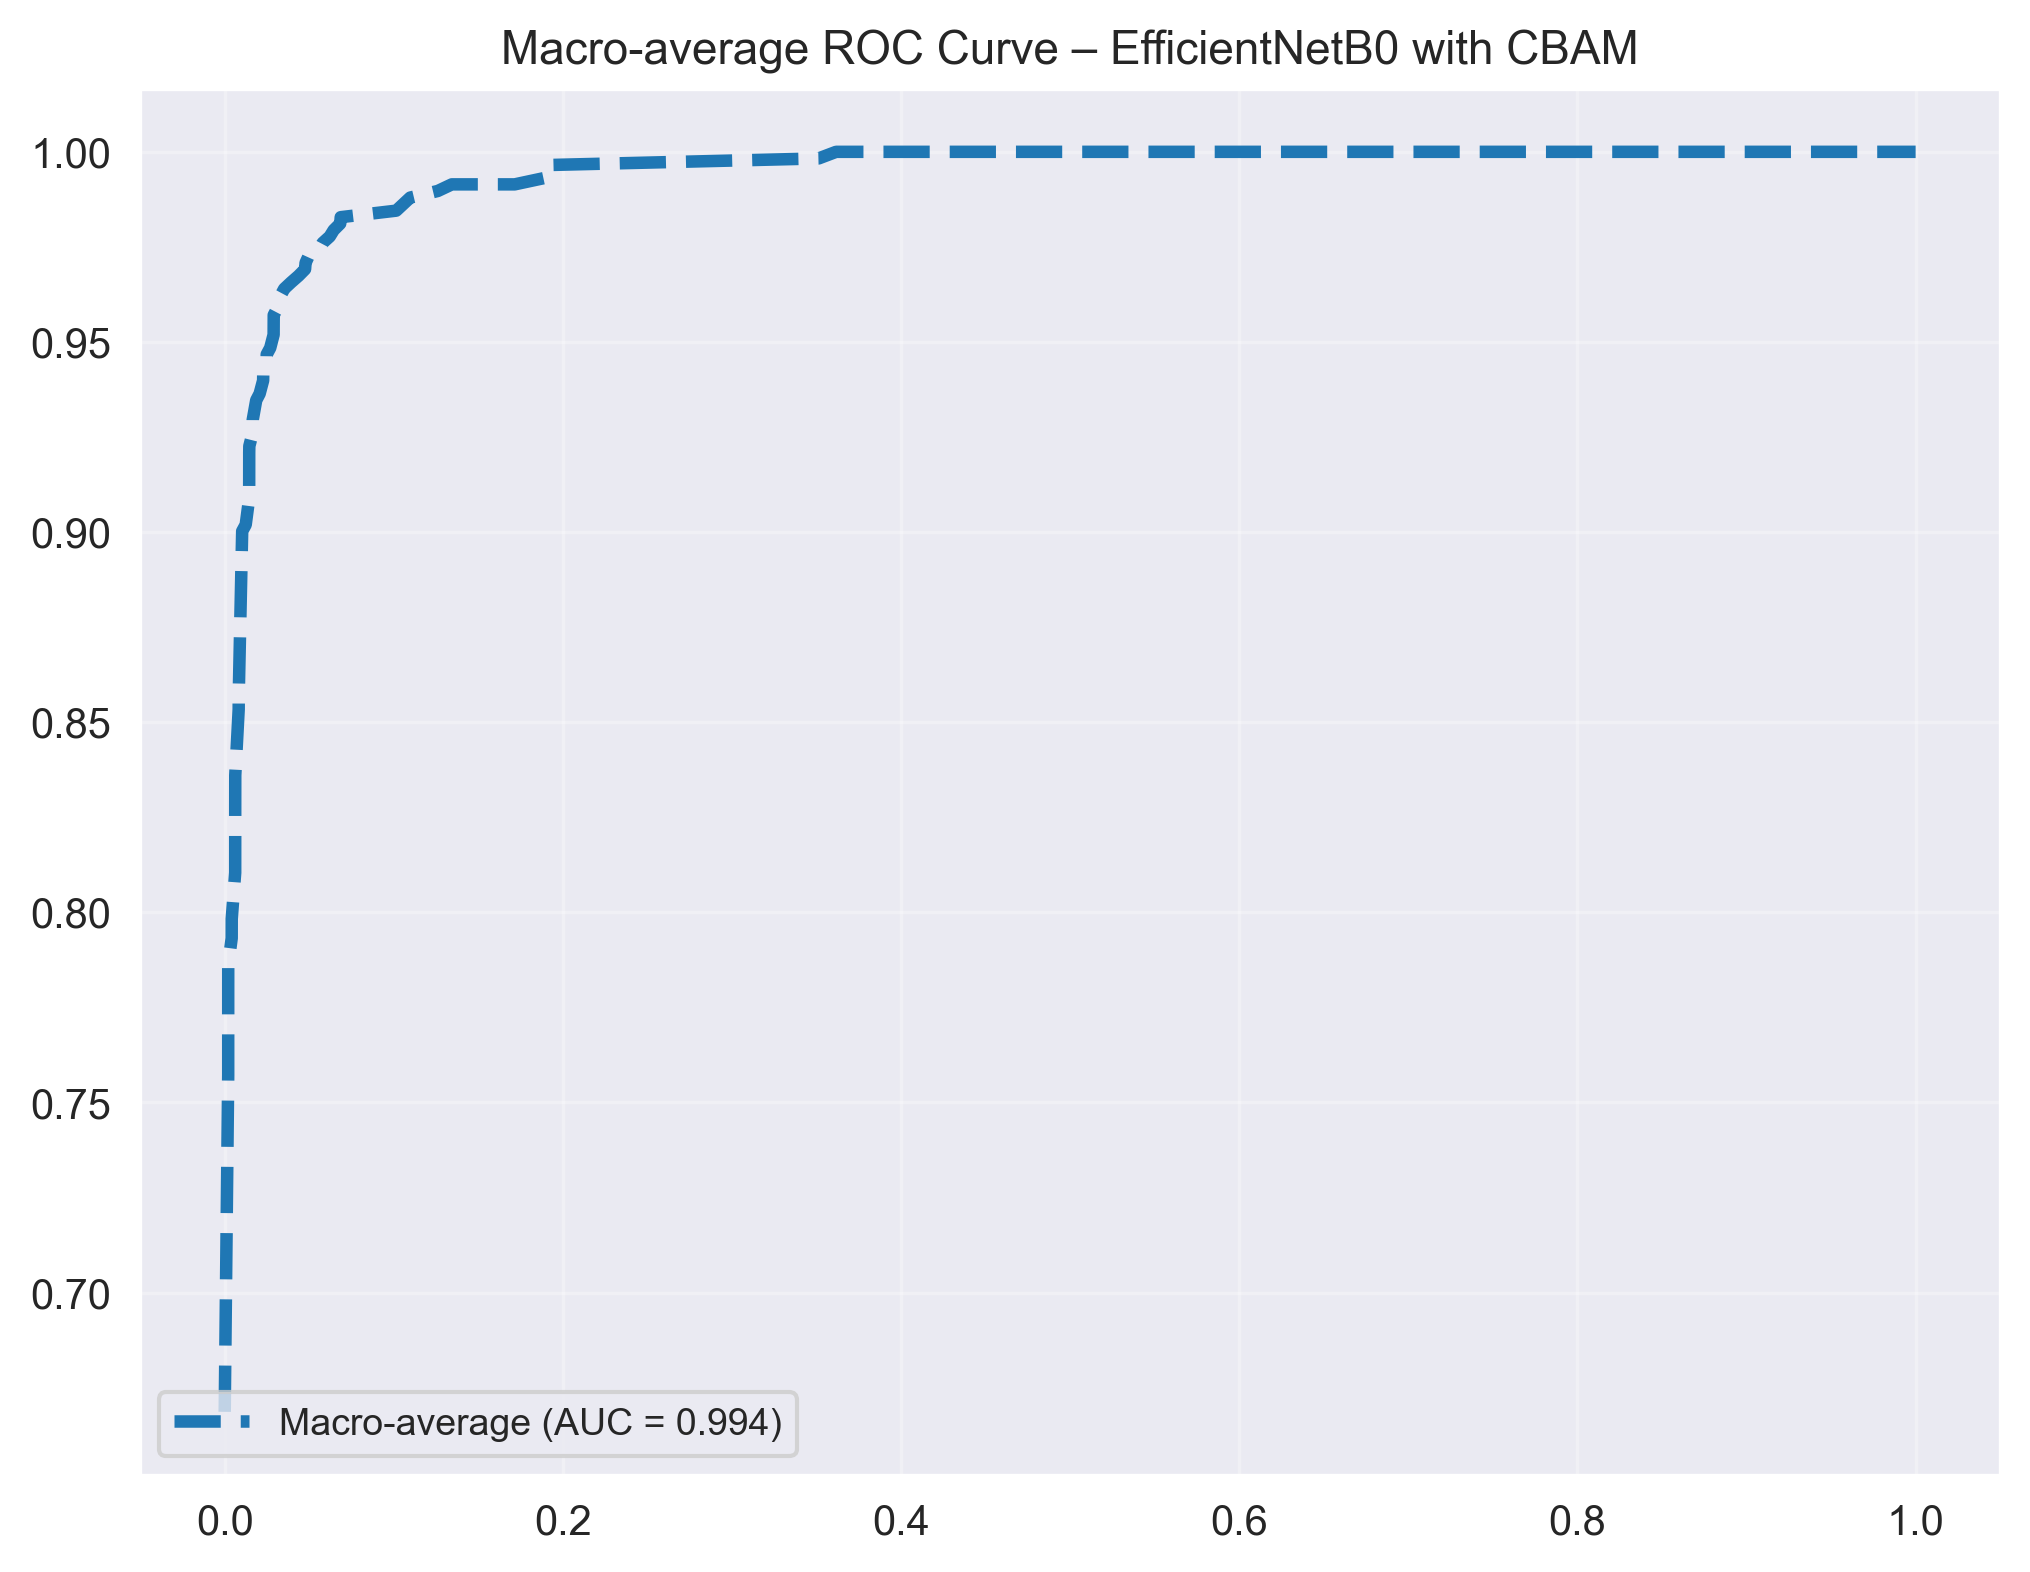

In [ ]:
# Compute macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= n_classes
macro_auc = auc(all_fpr, mean_tpr)
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(all_fpr, mean_tpr, linestyle='--', linewidth=3,
         label=f"Macro-average (AUC = {macro_auc:.3f})")
plt.title("Macro-average ROC Curve – EfficientNetB0 with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(y_test, y_score, average='macro')
weighted_auc = roc_auc_score(y_test, y_score, average='weighted')

print("Macro AUC:", macro_auc)
print("Weighted AUC:", weighted_auc)


Macro AUC: 0.9932776556153634
Weighted AUC: 0.9932662790404373


19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step


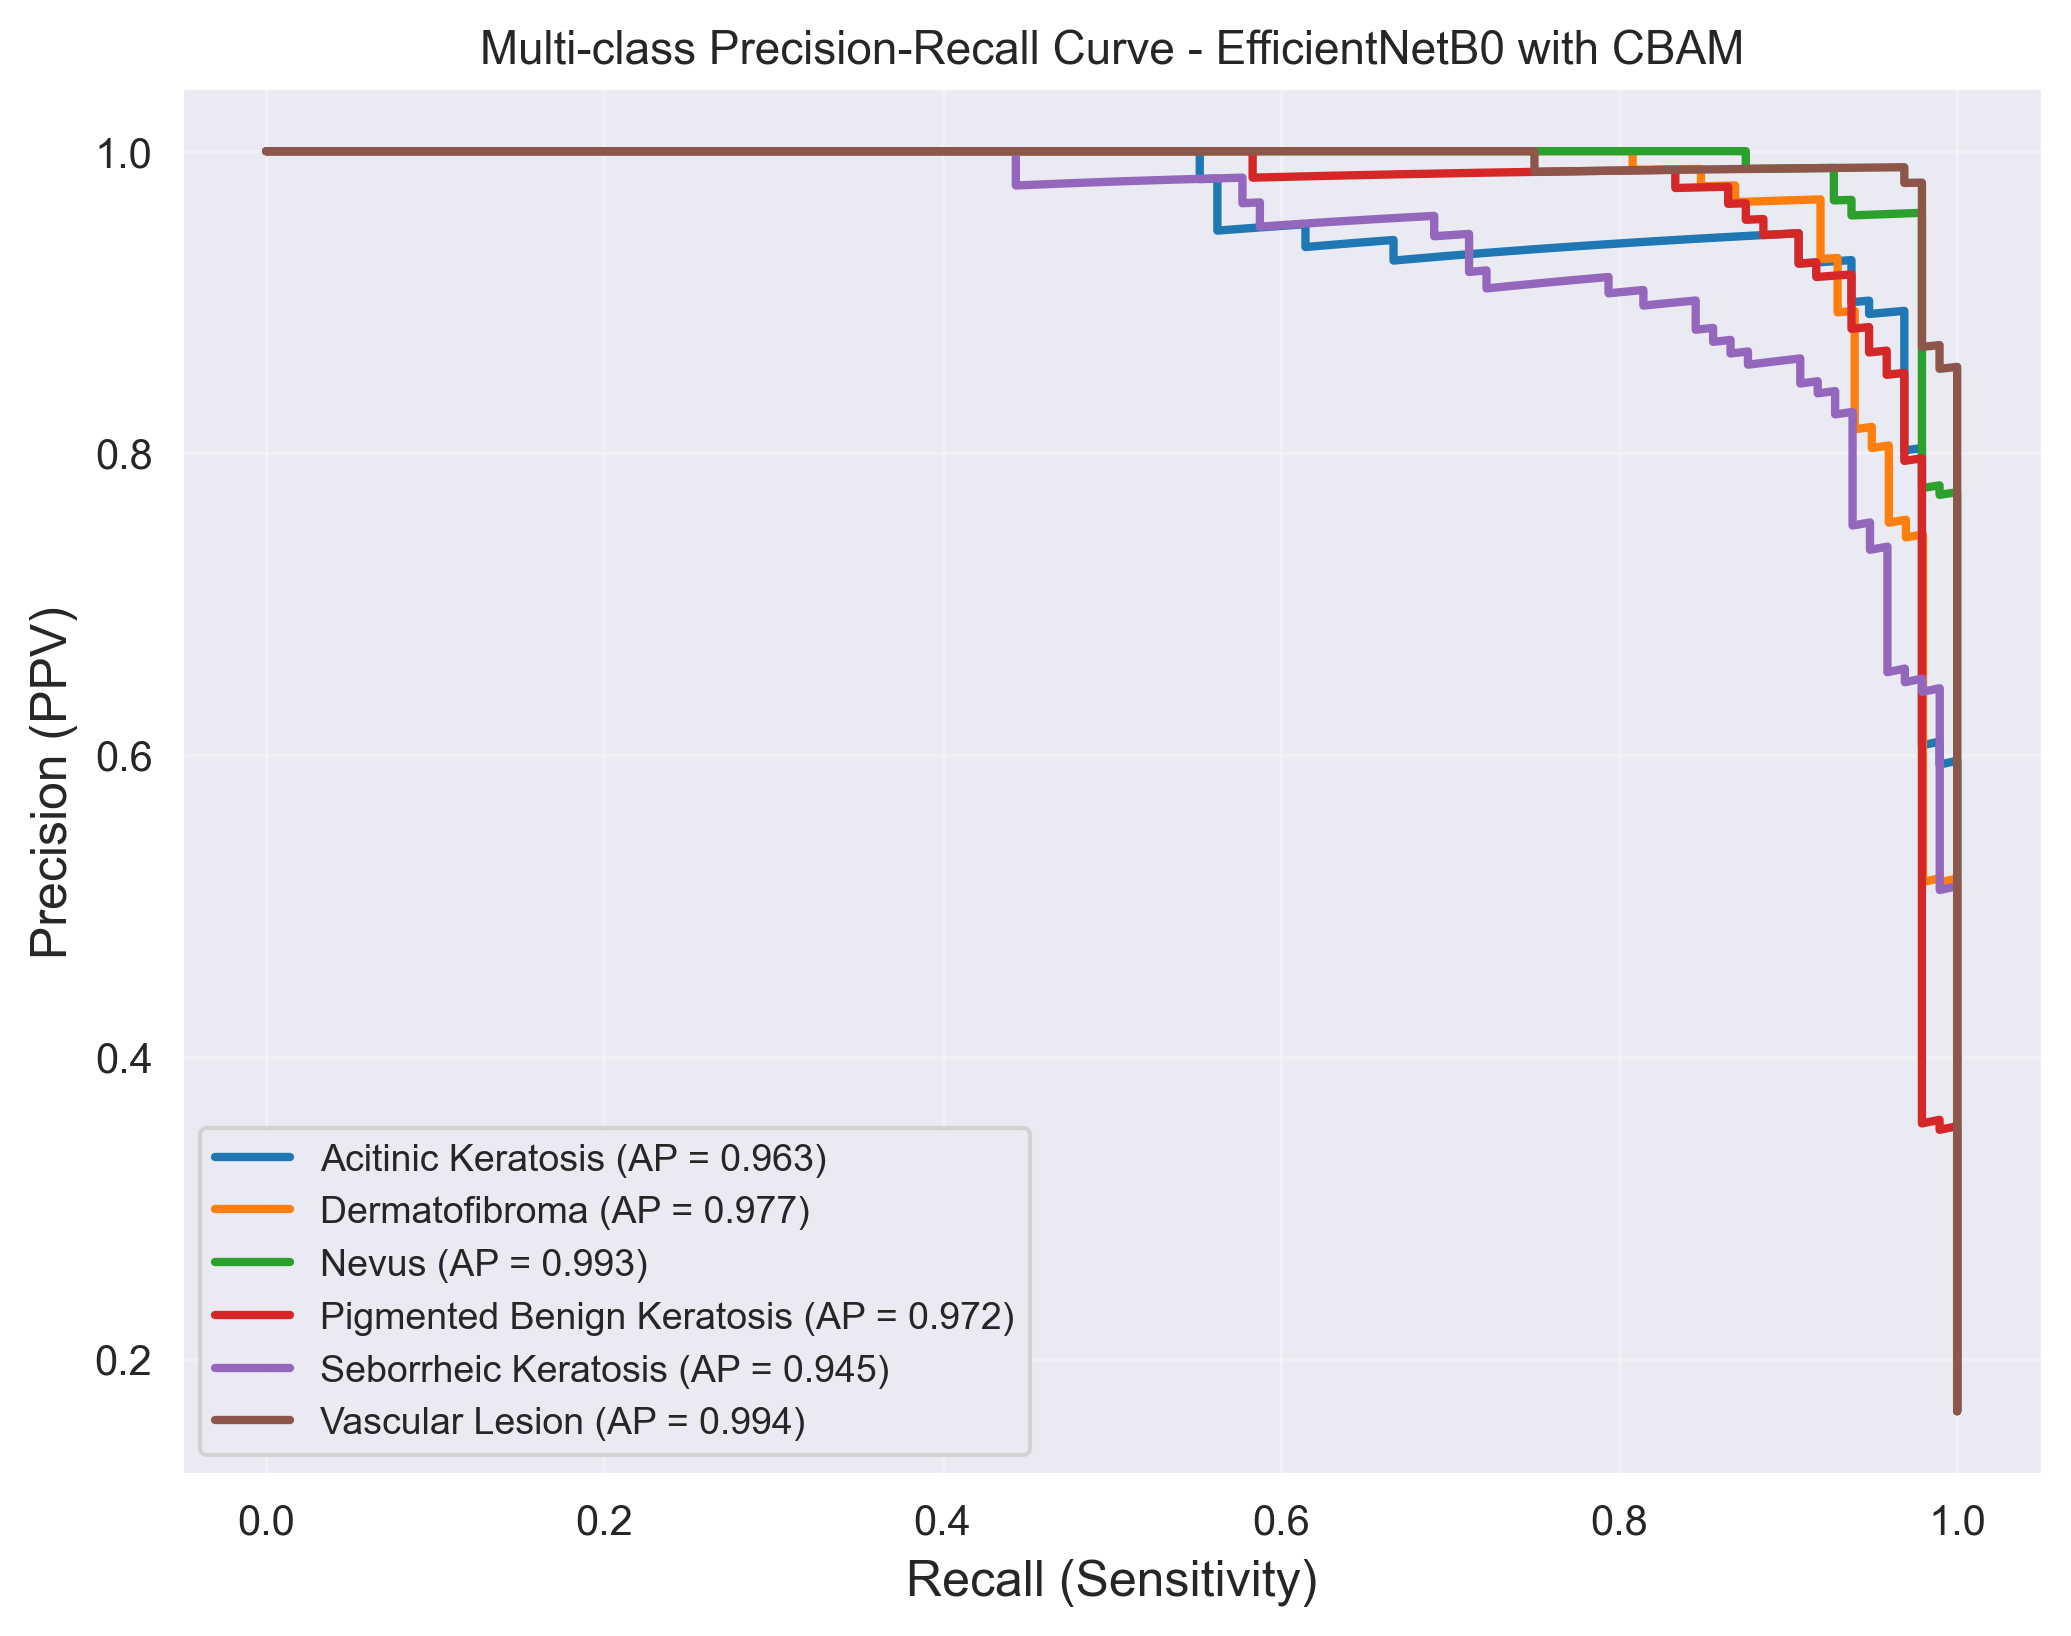

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Predict probabilities (NOT argmax)
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

precision = dict()
recall = dict()
avg_precision = dict()

# Compute PR curve and Average Precision (AP) for each class
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i], y_score[:, i]
    )
    avg_precision[i] = average_precision_score(
        y_true_bin[:, i], y_score[:, i]
    )

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(recall[i], precision[i], linewidth=2,
             label=f"{classes[i]} (AP = {avg_precision[i]:.3f})")

plt.xlabel("Recall (Sensitivity)", fontsize=12)
plt.ylabel("Precision (PPV)", fontsize=12)
plt.title("Multi-class Precision-Recall Curve - EfficientNetB0 with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

# Save high-resolution image
plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches='tight')

plt.show()


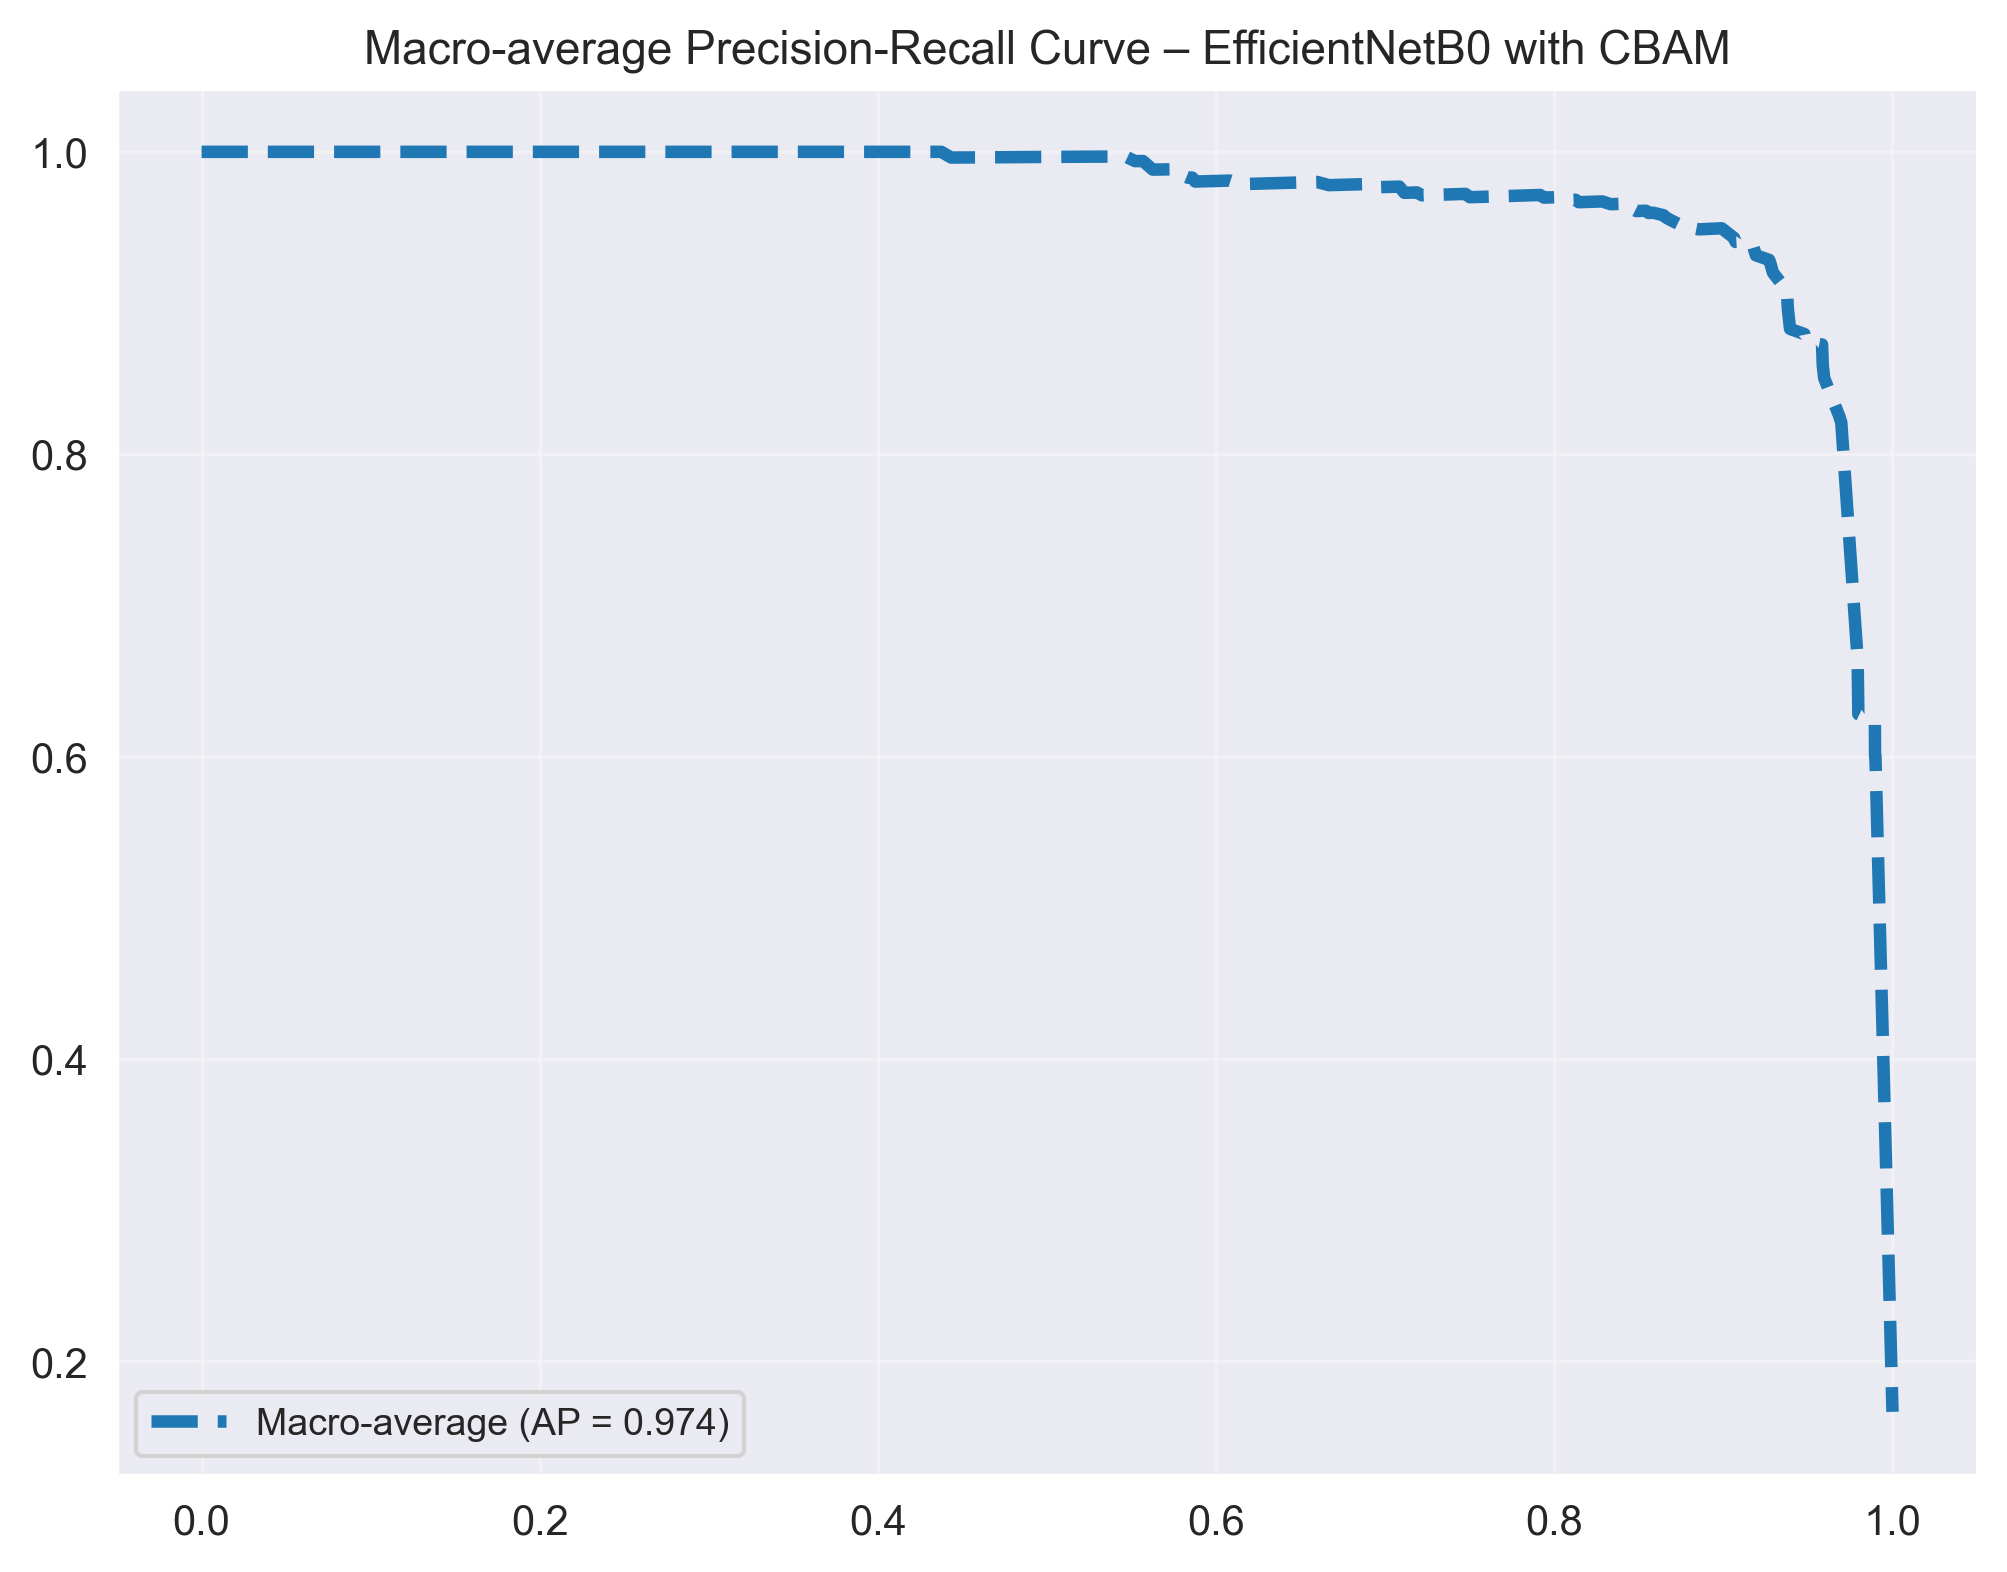

In [ ]:
# Compute macro-average PR
all_recall = np.unique(np.concatenate([recall[i] for i in range(n_classes)]))
mean_precision = np.zeros_like(all_recall)

for i in range(n_classes):
    mean_precision += np.interp(all_recall, recall[i][::-1], precision[i][::-1])

mean_precision /= n_classes

macro_ap = np.mean(list(avg_precision.values()))
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(all_recall, mean_precision, linestyle='--', linewidth=3,
         label=f"Macro-average (AP = {macro_ap:.3f})")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.title("Macro-average Precision-Recall Curve – EfficientNetB0 with CBAM", fontsize=11)

plt.show()

In [ ]:
model.save("CBAM_EfficientNetB0_model.h5")

In [ ]:
model.save("CBAM_EfficientNetB0_model.keras")